## LexisNexis - Detecting Fraudulent Insurance Claims

### Mukundan Thanigaivelan

In this notebook, we train Random Forest models.

### Import libraries and data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time, math

from sklearn.datasets import make_classification
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
  accuracy_score,
  precision_score,
  recall_score,
  average_precision_score,
  f1_score,
  confusion_matrix,
  classification_report
)

In [3]:
df = pd.read_csv('Mukundan_filtered_feature_engineered_fraud_oracle.csv')
df.shape

(15420, 16)

### Prepare data

In [4]:
# Split - train on 1994, test on 1995
train = df.loc[df['Year'] == 1994, :]
test = df.loc[df['Year'] == 1995, :]

In [5]:
X_train = train.drop(columns = ['Year', 'FraudFound_P'])
y_train = train['FraudFound_P']
X_test = test.drop(columns = ['Year', 'FraudFound_P'])
y_test = test['FraudFound_P']

### Tune for best Random Forest hyperparameters

In [6]:
# Identify feature types
numeric_cols = X_train.select_dtypes(
  include=["number"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
  include=["object"]
).columns.tolist()

In [7]:
# Categorical columns: one-hot encode
categorical_pipeline = Pipeline([
  ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [8]:
# Apply the appropriate transformations
preprocessor = ColumnTransformer([
  ("numeric", "passthrough", numeric_cols),
  ("categorical", categorical_pipeline, categorical_cols)
])

In [9]:
rf_pipeline = Pipeline([
  ("preprocessor", preprocessor),
  ("classifier", RandomForestClassifier(random_state=42))
])

In [10]:
# Define the hyperparameter search space
param_dist = {
  'classifier__n_estimators': [100, 200, 300, 500],
  'classifier__max_depth': [None, 10, 20, 30, 40],
  'classifier__min_samples_split': [2, 5, 10],
  'classifier__min_samples_leaf': [1, 2, 4],
  'classifier__max_features': ['sqrt', 'log2', 0.5],
  'classifier__bootstrap': [True, False]
}

# Initialize the base model and tuner
tuner = RandomizedSearchCV(
  estimator=rf_pipeline,
  param_distributions=param_dist,
  n_iter=50,
  cv=5,
  scoring='average_precision',
  n_jobs=-1,
  random_state=42,
  verbose=1
)

# Run the search and inspect results
tuner.fit(X_train, y_train)

print("Best Parameters:", tuner.best_params_)
print("Best CV Score:", tuner.best_score_)

# Evaluate the best model on the test set
best_rf = tuner.best_estimator_

# Predict probabilities
y_pred_proba = best_rf.predict_proba(X_test)[:, 1]

# Calculate test PR-AUC
test_pr_auc = average_precision_score(y_test, y_pred_proba)
print("Test PR-AUC:", test_pr_auc)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Parameters: {'classifier__n_estimators': 300, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'log2', 'classifier__max_depth': 10, 'classifier__bootstrap': False}
Best CV Score: 0.22768363777309672
Test PR-AUC: 0.16532906191590382


### Train Random Forest models

- Use optimal hyperparameters from tuner

In [11]:
# Combine preprocessing and logistic regression
model = Pipeline([
  ("preprocessor", preprocessor),
  ("random_forest", RandomForestClassifier(
    n_estimators=300,
    min_samples_split=10,
    min_samples_leaf=2,
    max_features="log2",
    max_depth=10,
    bootstrap=False,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
  ))
])

In [12]:
# Train
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [13]:
# Evaluate
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, y_prob):.4f}")

Accuracy:  0.6443
Precision: 0.1276
Recall:    0.8804
F1-score:  0.2229
PR-AUC:    0.1719


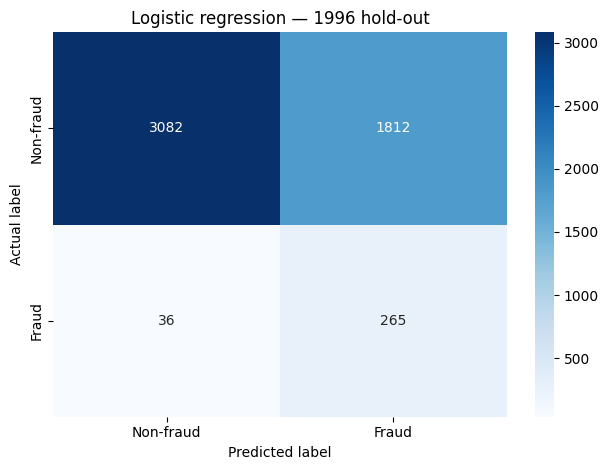

Correctly identified non-fraud: 3082
False alarms: 1812
Missed fraud: 36
Fraud cases caught: 265


In [14]:
matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-fraud', 'Fraud'], yticklabels=['Non-fraud', 'Fraud'])
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.title('Logistic regression — 1996 hold-out')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = matrix.ravel()
print('Correctly identified non-fraud:', tn)
print('False alarms:', fp)
print('Missed fraud:', fn)
print('Fraud cases caught:', tp)